# EquityLab public readout

This notebook recomputes the main tests in the README from the released portfolio-level data. It does not contain the private research engine, holdings or coefficients.

**Short version:** the main goal is to beat conventional MPT. The dynamic models did on ending wealth, and mostly still lead MPT matched to their own risk, though without a statistically clear gap. Beating passive benchmarks would be a bonus, and that depended on NVDA. All results are exploratory.

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd


def find_public_repo(explicit_root=None):
    """Find the repository from EQUITYLAB_PUBLIC_ROOT or the working directory."""
    cwd = Path.cwd().resolve()
    supplied = explicit_root or os.getenv("EQUITYLAB_PUBLIC_ROOT", "").strip()
    candidates = [Path(supplied).expanduser()] if supplied else []
    candidates += [cwd, *cwd.parents]
    for candidate in candidates:
        if (candidate / "results" / "selected_primary_results.csv").is_file():
            return candidate.resolve()
    raise FileNotFoundError(
        "Cannot find results/. Open this notebook from the repository, "
        "or set EQUITYLAB_PUBLIC_ROOT to the repository path."
    )


root = find_public_repo()
results = root / "results"
primary = pd.read_csv(results / "selected_primary_results.csv")
hybrid = pd.read_csv(results / "selected_hybrid_results.csv")

monthly_path = results / "selected_monthly_net_wealth.csv"
if not monthly_path.is_file():
    raise FileNotFoundError(
        "Monthly data is missing: results/selected_monthly_net_wealth.csv"
    )
monthly = pd.read_csv(monthly_path, parse_dates=["period_end"])
diagnostics = pd.read_csv(results / "public_market_exposure_diagnostics.csv")

STATE_SPACE = "EL / Hierarchical state-space"
KALMAN = "EL / Quality low-rank Kalman"
DYNAMIC = [STATE_SPACE, KALMAN]
CONTROL = "EquityLab"  # legacy CSV label for the historical-mean control
BLEND = "SPY / T-bills"


## How to read the labels

- **Dynamic models:** hierarchical state-space and quality low-rank Kalman. Both were chosen for presentation after the results were known.
- **`EquityLab` in older CSV columns:** the historical-mean coefficient control, not the intended dynamic system.
- **`Plain MPT` and `Corrected MPT`:** MPT / Historical mean and MPT / Shrinkage.
- **`Ex-ante-matched MPT`:** MPT matched to the control's estimated risk, not to the dynamic portfolios.

The README has the [full glossary](../README.md#what-is-being-compared).

## Check the released data

Each series should have 36 months, and compounding its monthly returns from 10,000 should reproduce its reported ending wealth.

In [2]:
keys = ["representation", "mandate", "strategy"]
series = monthly.sort_values("period_end").groupby(keys)
compounded = series["net_return"].apply(lambda r: 10_000 * (1 + r).prod())
reported = series["wealth_end"].last()

assert series.size().eq(36).all()
assert (compounded - reported).abs().max() < 0.5
print(f"{series.ngroups} series, {monthly.period_end.nunique()} months: "
      f"{monthly.period_end.min():%b %Y} to {monthly.period_end.max():%b %Y}")
print(f"Largest reconciliation gap: {(compounded - reported).abs().max():.4f} units")


54 series, 36 months: Jan 2023 to Dec 2025
Largest reconciliation gap: 0.0000 units


## Scorecard

These tables reproduce the summary at the top of the README: the main goal first, then each mandate against its fair passive benchmark, then the supporting tests.

Most counts are out of **12 comparisons**, which are 2 dynamic models × 2 representations (Grouped, Hierarchical) × 3 mandates (Growth, Balanced, Defensive). Each comparison scores one model in one setup over the same 36 months. They share a market period and asset list, so they are not 12 independent experiments.

In [3]:
def hac_tstat(x, lags=3):
    """t-statistic for a mean, with Newey-West (Bartlett) standard errors."""
    x = np.asarray(x, dtype=float)
    mean, n = x.mean(), len(x)
    e = x - mean
    variance = e @ e / n
    for k in range(1, lags + 1):
        variance += 2 * (1 - k / (lags + 1)) * (e[k:] @ e[:-k]) / n
    return mean / np.sqrt(variance / n)


wealth = reported.unstack("strategy")
returns = monthly.pivot_table(
    index=["representation", "mandate", "period_end"],
    columns="strategy", values="net_return",
)

rows = []
for (rep, mandate), g in returns.groupby(level=[0, 1]):
    for model in DYNAMIC:
        rows.append({
            "representation": rep, "mandate": mandate, "model": model.removeprefix("EL / "),
            "ending_wealth": wealth.loc[(rep, mandate), model],
            "vs_blend": wealth.loc[(rep, mandate), model] - wealth.loc[(rep, mandate), BLEND],
            "vs_control": wealth.loc[(rep, mandate), model] - wealth.loc[(rep, mandate), CONTROL],
            "t_vs_control": hac_tstat(g[model] - g[CONTROL]),
        })
dynamic = pd.DataFrame(rows)

def sharpe(x, cash):
    excess = x - cash
    return excess.mean() / excess.std() * np.sqrt(12)


MPT_LABELS = {"Plain MPT": "MPT / Historical mean", "Corrected MPT": "MPT / Shrinkage",
              "Ex-ante-matched MPT": "MPT matched to control's estimated risk"}
rows = []
for (rep, mandate), g in returns.groupby(level=[0, 1]):
    for model in DYNAMIC:
        for mpt in MPT_LABELS:
            rows.append({
                "mpt": mpt,
                "wealth": wealth.loc[(rep, mandate), model] > wealth.loc[(rep, mandate), mpt],
                "sharpe": sharpe(g[model], g["T-bills"]) > sharpe(g[mpt], g["T-bills"]),
                "gap": hac_tstat(g[model] - g[mpt]) > 1.96,
                "more_volatile": g[model].std() > g[mpt].std(),
            })
mpt_scorecard = (pd.DataFrame(rows).groupby("mpt").sum().rename(index=MPT_LABELS)
                 .rename(columns={"wealth": "higher_wealth", "sharpe": "higher_sharpe",
                                  "gap": "gap_above_zero"}))
mpt_scorecard["comparisons"] = 12

dyn_diag = diagnostics[diagnostics.strategy.isin(DYNAMIC)]
matched = dyn_diag[dyn_diag.blend_match_status == "matched_retrospectively"]

scorecard = pd.DataFrame([
    ("Dynamic above historical-mean control", f"{(dynamic.vs_control > 0).sum()} of {len(dynamic)}"),
    ("Dynamic SPY-adjusted return, 95% interval above zero",
     f"{(dyn_diag.alpha_95ci_low_annual > 0).sum()} of {len(dyn_diag)}"),
    ("Dynamic above same-volatility SPY/T-bill mix",
     f"{(matched.wealth_minus_blend > 0).sum()} of {len(matched)} matchable"),
    ("Control above MPT / Historical mean",
     f"{(primary.equitylab_wealth > primary.mpt_plain_wealth).sum()} of {len(primary)}"),
    ("Control above MPT matched on estimated risk",
     f"{(primary.equitylab_wealth > primary.mpt_exact_exante_wealth).sum()} of {len(primary)}"),
    ("EquityLab information improved shared MPT (27 months)",
     f"{(hybrid.equitylab_information_wealth > hybrid.mpt_information_wealth).sum()} of {len(hybrid)}"),
], columns=["Test", "Result"])

fair = dynamic.assign(benchmark=np.where(dynamic.mandate == "Growth", "SPY", BLEND))
fair["beat"] = [wealth.loc[(r.representation, r.mandate), f"EL / {r.model}"]
                > wealth.loc[(r.representation, r.mandate), r.benchmark]
                for r in fair.itertuples()]
passive = (fair.groupby(["mandate", "benchmark"]).beat.agg(["sum", "count"])
           .rename(columns={"sum": "above", "count": "comparisons"}).reset_index())

display(mpt_scorecard)
display(passive)
scorecard


,higher_wealth,higher_sharpe,gap_above_zero,more_volatile,comparisons
mpt,,,,,
MPT / Shrinkage,12,12,7,12,12
MPT matched to control's estimated risk,10,10,1,12,12
MPT / Historical mean,12,8,3,12,12


,mandate,benchmark,above,comparisons
0,Balanced,SPY / T-bills,0,4
1,Defensive,SPY / T-bills,2,4
2,Growth,SPY,2,4


,Test,Result
0,Dynamic above historical-mean control,6 of 12
1,"Dynamic SPY-adjusted return, 95% interval abov...",0 of 12
2,Dynamic above same-volatility SPY/T-bill mix,1 of 8 matchable
3,Control above MPT / Historical mean,6 of 6
4,Control above MPT matched on estimated risk,5 of 6
5,EquityLab information improved shared MPT (27 ...,4 of 6


## Dynamic models against the blend and the control

Positive values mean the dynamic model finished ahead. `t_vs_control` tests the monthly return difference, using three-lag Newey–West errors.

In [4]:
dynamic.sort_values("vs_blend", ascending=False).round(
    {"ending_wealth": 0, "vs_blend": 0, "vs_control": 0, "t_vs_control": 2}
).reset_index(drop=True)


,representation,mandate,model,ending_wealth,vs_blend,vs_control,t_vs_control
0,Grouped,Growth,Hierarchical state-space,21175.0,2659.0,4155.0,2.05
1,Grouped,Growth,Quality low-rank Kalman,20209.0,1693.0,3188.0,1.62
2,Hierarchical,Defensive,Hierarchical state-space,13717.0,365.0,-304.0,-0.71
3,Hierarchical,Defensive,Quality low-rank Kalman,13552.0,201.0,-469.0,-0.90
4,Grouped,Defensive,Quality low-rank Kalman,12932.0,-420.0,-91.0,-0.20
5,Grouped,Defensive,Hierarchical state-space,12905.0,-446.0,-117.0,-0.18
6,Hierarchical,Balanced,Hierarchical state-space,14685.0,-2426.0,936.0,0.98
7,Hierarchical,Growth,Hierarchical state-space,15968.0,-2548.0,-1541.0,-0.58
8,Hierarchical,Balanced,Quality low-rank Kalman,14520.0,-2592.0,771.0,0.63
9,Grouped,Balanced,Hierarchical state-space,14405.0,-2706.0,863.0,0.74


Grouped Growth is the only configuration where both models clearly beat SPY. The same models finished below SPY in Hierarchical Growth, so the result depends on the feature representation.

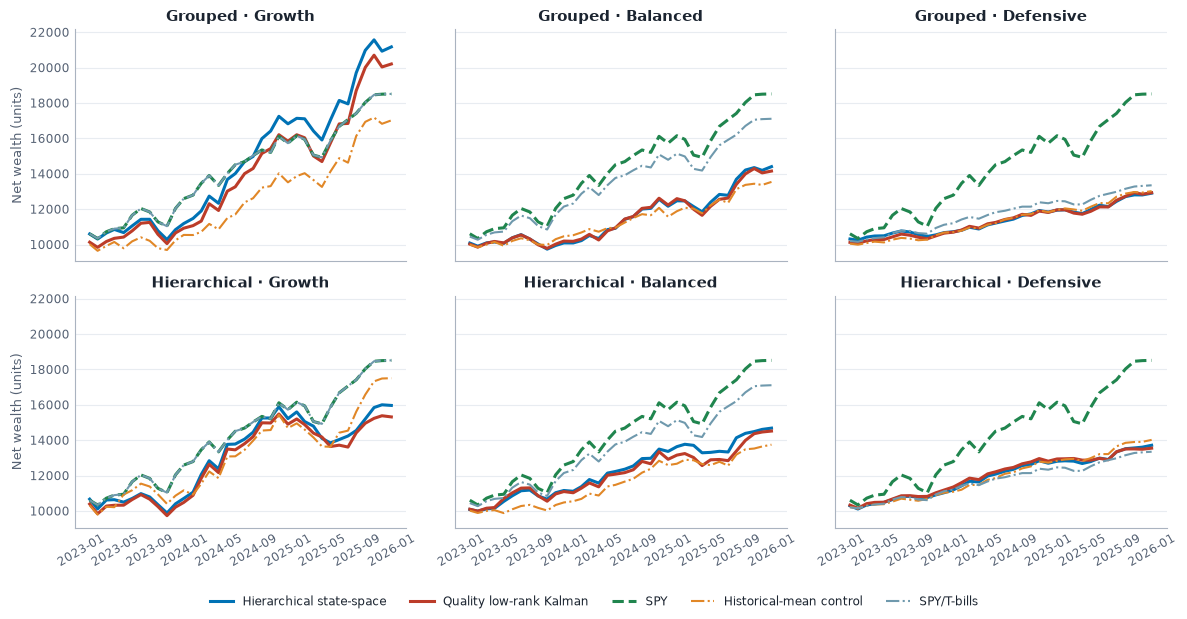

In [5]:
import sys

import matplotlib.pyplot as plt

sys.path.insert(0, str(root / "analysis"))
import chart_style as cs

cs.apply()
LINES = [
    (STATE_SPACE, "Hierarchical state-space", cs.STATE_SPACE, "-", 2.2),
    (KALMAN, "Quality low-rank Kalman", cs.KALMAN, "-", 2.2),
    ("SPY", "SPY", cs.SPY, "--", 2.2),
    (CONTROL, "Historical-mean control", cs.CONTROL, "-.", 1.5),
    (BLEND, "SPY/T-bills", cs.SPY_TBILL, "-.", 1.5),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), sharex=True, sharey=True)
for i, rep in enumerate(["Grouped", "Hierarchical"]):
    for j, mandate in enumerate(["Growth", "Balanced", "Defensive"]):
        ax = axes[i, j]
        panel = monthly[(monthly.representation == rep) & (monthly.mandate == mandate)]
        for strategy, label, color, style, width in LINES:
            s = panel[panel.strategy == strategy].sort_values("period_end")
            ax.plot(s.period_end, s.wealth_end, color=color, ls=style, lw=width, label=label)
        ax.set_title(f"{rep} · {mandate}")
        ax.grid(axis="y")
        ax.tick_params(axis="x", labelrotation=30)
axes[0, 0].set_ylabel("Net wealth (units)")
axes[1, 0].set_ylabel("Net wealth (units)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


## Market exposure

Each portfolio's excess return is regressed on SPY's excess return. An interval that crosses zero means the data cannot distinguish the residual return from no residual return at all.

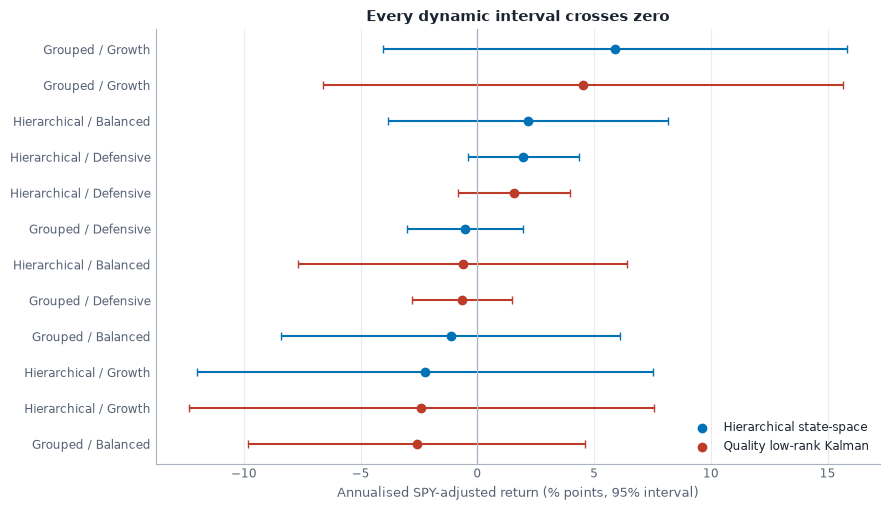

Intervals above zero: 1 of 18


,representation,mandate,strategy,market_beta,alpha,ci_low,ci_high,t
0,Hierarchical,Defensive,Historical-mean control,0.197,0.033,0.009,0.057,2.709


In [6]:
exposure = diagnostics[["representation", "mandate", "strategy", "market_beta",
                        "annualised_arithmetic_alpha", "alpha_95ci_low_annual",
                        "alpha_95ci_high_annual", "alpha_hac_t"]].copy()
exposure["strategy"] = exposure.strategy.replace({CONTROL: "Historical-mean control"})
exposure = exposure.rename(columns={
    "annualised_arithmetic_alpha": "alpha", "alpha_95ci_low_annual": "ci_low",
    "alpha_95ci_high_annual": "ci_high", "alpha_hac_t": "t",
})

fig, ax = plt.subplots(figsize=(9, 5.2))
plot = exposure[exposure.strategy.isin(DYNAMIC)].sort_values("alpha").reset_index(drop=True)
for y, r in plot.iterrows():
    color = cs.STATE_SPACE if r.strategy == STATE_SPACE else cs.KALMAN
    ax.errorbar(100 * r.alpha, y, color=color, fmt="o", capsize=3,
                xerr=[[100 * (r.alpha - r.ci_low)], [100 * (r.ci_high - r.alpha)]])
ax.set_yticks(range(len(plot)), plot.representation + " / " + plot.mandate)
ax.axvline(0, color=cs.AXIS, lw=0.9)
ax.grid(axis="x")
ax.set_xlabel("Annualised SPY-adjusted return (% points, 95% interval)")
ax.set_title("Every dynamic interval crosses zero")
ax.scatter([], [], color=cs.STATE_SPACE, label="Hierarchical state-space")
ax.scatter([], [], color=cs.KALMAN, label="Quality low-rank Kalman")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

above_zero = exposure[exposure.ci_low > 0]
print(f"Intervals above zero: {len(above_zero)} of {len(exposure)}")
above_zero.round(3).reset_index(drop=True)


The one interval above zero belongs to the historical-mean control, not a dynamic model. One result among 18 related tests needs a fresh sample before it can be trusted.

## Historical-mean control against MPT

These comparisons use the non-dynamic control. The first two MPT columns are not risk-matched, and MPT often held much less equity.

In [7]:
control = primary[["representation", "mandate", "equitylab_wealth", "mpt_plain_wealth",
                   "mpt_corrected_wealth", "mpt_exact_exante_wealth",
                   "equitylab_excess_sharpe", "exact_mpt_excess_sharpe",
                   "paired_excess_hac_t"]].rename(columns={
    "equitylab_wealth": "control", "mpt_plain_wealth": "mpt_mean",
    "mpt_corrected_wealth": "mpt_shrinkage", "mpt_exact_exante_wealth": "mpt_risk_matched",
    "equitylab_excess_sharpe": "control_sharpe", "exact_mpt_excess_sharpe": "matched_sharpe",
    "paired_excess_hac_t": "paired_t",
})
control.round({"control": 0, "mpt_mean": 0, "mpt_shrinkage": 0, "mpt_risk_matched": 0,
               "control_sharpe": 2, "matched_sharpe": 2, "paired_t": 2})


,representation,mandate,control,mpt_mean,mpt_shrinkage,mpt_risk_matched,control_sharpe,matched_sharpe,paired_t
0,Grouped,Growth,17020.0,11545.0,11568.0,15881.0,1.12,0.98,0.61
1,Grouped,Balanced,13542.0,12358.0,11602.0,13267.0,0.77,0.76,0.35
2,Grouped,Defensive,13022.0,12497.0,11657.0,12569.0,1.19,0.90,1.13
3,Hierarchical,Growth,17509.0,11545.0,11568.0,17696.0,1.08,1.35,-0.01
4,Hierarchical,Balanced,13749.0,12358.0,11602.0,12630.0,0.98,0.51,1.49
5,Hierarchical,Defensive,14021.0,12497.0,11657.0,12802.0,1.88,1.04,2.30


Hierarchical Growth is the exception: risk-matched MPT finished ahead on both wealth and Sharpe. Only Hierarchical Defensive has a paired t-statistic above 1.96.

## H3: EquityLab information inside MPT

This is a separate 27-month experiment using one shared optimiser. It does not test the complete EquityLab strategy.

In [8]:
h3 = hybrid[["representation", "mandate", "equitylab_information_wealth",
             "mpt_information_wealth", "paired_excess_hac_t"]].copy()
h3["difference"] = h3.equitylab_information_wealth - h3.mpt_information_wealth
h3.round({"equitylab_information_wealth": 0, "mpt_information_wealth": 0,
          "paired_excess_hac_t": 2, "difference": 0})


,representation,mandate,equitylab_information_wealth,mpt_information_wealth,paired_excess_hac_t,difference
0,Grouped,Growth,12345.0,11841.0,2.82,504.0
1,Grouped,Balanced,11389.0,11486.0,-0.70,-97.0
2,Grouped,Defensive,11539.0,11333.0,0.81,206.0
3,Hierarchical,Growth,12150.0,11841.0,1.60,309.0
4,Hierarchical,Balanced,11197.0,11486.0,-1.77,-289.0
5,Hierarchical,Defensive,11821.0,11333.0,1.39,487.0


## Own-risk MPT and removing NVDA

The whole pipeline was rerun without NVDA. MPT was also matched to each dynamic model's own estimated risk. Paths with solver failures are incomplete and not counted.

In [9]:
robust = pd.read_csv(results / "nvda_and_own_risk_robustness.csv")


def tally(g):
    done = g[g.own_risk_mpt_complete]
    return pd.Series({
        "above_mpt_mean": (g.ending_wealth > g.mpt_historical_mean_wealth).sum(),
        "above_mpt_shrinkage": (g.ending_wealth > g.mpt_shrinkage_wealth).sum(),
        "above_fair_passive": (g.ending_wealth > g.fair_passive_wealth).sum(),
        "above_control": (g.ending_wealth > g.control_wealth).sum(),
        "own_risk_complete": len(done),
        "above_own_risk_mpt": (done.ending_wealth > done.own_risk_mpt_wealth).sum(),
        "higher_sharpe_own_risk": (done.model_sharpe > done.own_risk_mpt_sharpe).sum(),
        "gap_above_zero": (done.paired_hac_t > 1.96).sum(),
    })


robust.groupby("universe", sort=False)[list(robust.columns)].apply(tally).T


universe,with_nvda,without_nvda
above_mpt_mean,12,12
above_mpt_shrinkage,12,12
above_fair_passive,4,0
above_control,6,4
own_risk_complete,9,11
above_own_risk_mpt,8,11
higher_sharpe_own_risk,5,11
gap_above_zero,0,0


## Rerun without NVDA

The full pipeline, including Phase 1, was rerun on the other 43 instruments, so the coefficients carry nothing learned from NVDA. The tests below are recomputed from the released monthly results of both runs.

In [10]:
without = pd.read_csv(results / "without_nvda_monthly_net_wealth.csv", parse_dates=["period_end"])

check = without.sort_values("period_end").groupby(keys)
assert check.size().eq(36).all()
assert (check["net_return"].apply(lambda r: 10_000 * (1 + r).prod()) - check["wealth_end"].last()).abs().max() < 0.5
print(f"{check.ngroups} series without NVDA, all 36 months and reconciled")


def score_run(frame):
    final = frame.sort_values("period_end").groupby(keys)["wealth_end"].last().unstack("strategy")
    rets = frame.pivot_table(index=["representation", "mandate", "period_end"],
                             columns="strategy", values="net_return")
    rows = []
    for (rep, mandate), g in rets.groupby(level=[0, 1]):
        passive = "SPY" if mandate == "Growth" else BLEND
        for model in DYNAMIC:
            w = final.loc[(rep, mandate)]
            rows.append({
                "model": model,
                "mandate": mandate,
                "above_mpt_mean": w[model] > w["Plain MPT"],
                "above_mpt_shrinkage": w[model] > w["Corrected MPT"],
                "above_fair_passive": w[model] > w[passive],
                "above_control": w[model] > w[CONTROL],
                "sharpe_above_mpt_mean": sharpe(g[model], g["T-bills"]) > sharpe(g["Plain MPT"], g["T-bills"]),
                "gap_above_zero_mpt_mean": hac_tstat(g[model] - g["Plain MPT"]) > 1.96,
                "gap_above_zero_mpt_shrinkage": hac_tstat(g[model] - g["Corrected MPT"]) > 1.96,
            })
    return pd.DataFrame(rows)


with_scores = score_run(monthly)
without_scores = score_run(without)
tests = [c for c in with_scores.columns if c not in ("model", "mandate")]
pd.DataFrame({"with_nvda": with_scores[tests].sum(), "without_nvda": without_scores[tests].sum()})


54 series without NVDA, all 36 months and reconciled


,with_nvda,without_nvda
above_mpt_mean,12,12
above_mpt_shrinkage,12,12
above_fair_passive,4,0
above_control,6,4
sharpe_above_mpt_mean,8,12
gap_above_zero_mpt_mean,3,2
gap_above_zero_mpt_shrinkage,7,5


Each count is out of the same 12 comparisons: 2 models × 2 representations × 3 mandates. The wins over conventional MPT survive. The wins over the fair passive benchmark do not.

In [11]:
by_mandate = pd.DataFrame({
    "with_nvda": with_scores.groupby("mandate")["above_fair_passive"].sum(),
    "without_nvda": without_scores.groupby("mandate")["above_fair_passive"].sum(),
}).reindex(["Growth", "Balanced", "Defensive"])
by_mandate["comparisons"] = 4
by_mandate


,with_nvda,without_nvda,comparisons
mandate,,,
Growth,2,0,4
Balanced,0,0,4
Defensive,2,0,4


In [12]:
change = robust.pivot_table(index=["representation", "mandate", "model"], columns="universe",
                            values="ending_wealth")[["with_nvda", "without_nvda"]]
change["change"] = change["without_nvda"] - change["with_nvda"]
change = change.rename(index=lambda name: name.removeprefix("EL / "), level="model")
change.round(0).sort_values("change")


universe                                           with_nvda  without_nvda  \
representation mandate   model                                               
Grouped        Growth    Hierarchical state-space    21175.0       14784.0   
                         Quality low-rank Kalman     20209.0       14570.0   
Hierarchical   Growth    Hierarchical state-space    15968.0       14570.0   
               Balanced  Hierarchical state-space    14685.0       13595.0   
                         Quality low-rank Kalman     14520.0       13513.0   
               Defensive Hierarchical state-space    13717.0       12942.0   
                         Quality low-rank Kalman     13552.0       12801.0   
Grouped        Balanced  Hierarchical state-space    14405.0       14014.0   
               Defensive Quality low-rank Kalman     12932.0       12688.0   
                         Hierarchical state-space    12905.0       12851.0   
               Balanced  Quality low-rank Kalman     14155.0       14844.0   
Hierarchical   Growth    Quality low-rank Kalman     15319.0       16755.0   

universe                                           change  
representation mandate   model                             
Grouped        Growth    Hierarchical state-space -6391.0  
                         Quality low-rank Kalman  -5638.0  
Hierarchical   Growth    Hierarchical state-space -1398.0  
               Balanced  Hierarchical state-space -1090.0  
                         Quality low-rank Kalman  -1007.0  
               Defensive Hierarchical state-space  -774.0  
                         Quality low-rank Kalman   -751.0  
Grouped        Balanced  Hierarchical state-space  -391.0  
               Defensive Quality low-rank Kalman   -244.0  
                         Hierarchical state-space   -54.0  
               Balanced  Quality low-rank Kalman    689.0  
Hierarchical   Growth    Quality low-rank Kalman   1436.0

Ten of the 12 results fall, and the two Grouped Growth models fall the most. Two Kalman results rise, which shows the models also change their other holdings when NVDA is removed.

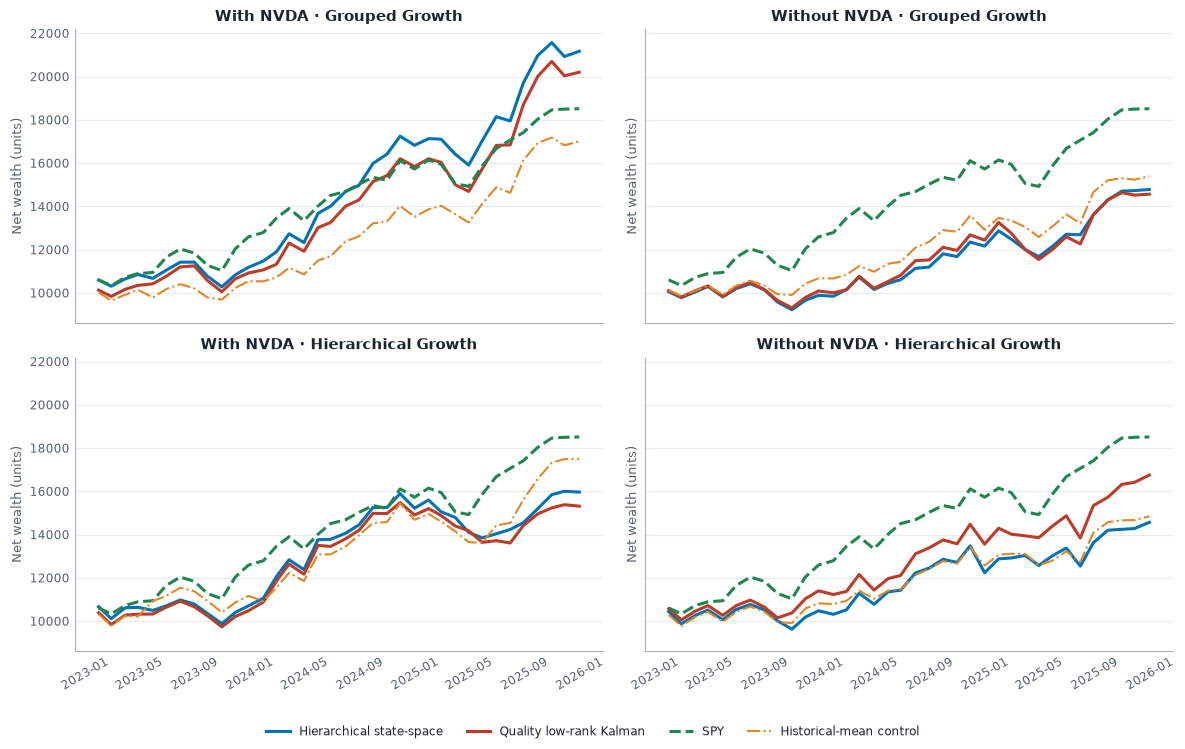

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, sharey=True)
for col, (frame, label) in enumerate([(monthly, "With NVDA"), (without, "Without NVDA")]):
    for row, rep in enumerate(["Grouped", "Hierarchical"]):
        ax = axes[row, col]
        panel = frame[(frame.representation == rep) & (frame.mandate == "Growth")]
        for strategy, name, color, style, width in LINES[:4]:
            s = panel[panel.strategy == strategy].sort_values("period_end")
            ax.plot(s.period_end, s.wealth_end, color=color, ls=style, lw=width, label=name)
        ax.set_title(f"{label} · {rep} Growth")
        ax.grid(axis="y")
        ax.tick_params(axis="x", labelrotation=30)
    axes[0, col].set_ylabel("Net wealth (units)")
    axes[1, col].set_ylabel("Net wealth (units)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


## Lead over MPT matched to each model's own risk

MPT is matched to each dynamic model's own estimated risk, in both runs. Paths with solver failures are incomplete and are not counted.

In [14]:
lead = robust[robust.own_risk_mpt_complete].assign(
    lead=lambda d: d.ending_wealth - d.own_risk_mpt_wealth,
    model=lambda d: d.model.str.removeprefix("EL / "),
)
lead = lead.pivot_table(index=["representation", "mandate", "model"], columns="universe", values="lead")
lead[["with_nvda", "without_nvda"]].round(0)


universe                                           with_nvda  without_nvda
representation mandate   model                                            
Grouped        Balanced  Hierarchical state-space      759.0        1091.0
                         Quality low-rank Kalman       749.0        1824.0
               Defensive Hierarchical state-space       50.0         654.0
                         Quality low-rank Kalman      -162.0         507.0
               Growth    Hierarchical state-space      919.0           NaN
                         Quality low-rank Kalman         NaN        1833.0
Hierarchical   Balanced  Hierarchical state-space     1164.0         898.0
                         Quality low-rank Kalman       964.0         504.0
               Defensive Hierarchical state-space      555.0         784.0
                         Quality low-rank Kalman       461.0         831.0
               Growth    Hierarchical state-space        NaN        2134.0
                         Quality low-rank Kalman         NaN        3889.0

## What this does and does not show

- **Shown:** the dynamic models beat conventional MPT on ending wealth in a cost-aware sequential evaluation, and that survives removing NVDA.
- **Not shown:** a statistically clear win over own-risk MPT, an edge over passive benchmarks without NVDA, or evidence that dynamic forecasting consistently improves on the control.
- **Main caveats:** 36 months in a strong equity market, models chosen with hindsight, a fixed 44-instrument universe not verified as point-in-time, and FX data that is not fully verified.

See the [limitations](../docs/limitations.md) for detail.